# Example of the aitlas toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import SPARCSDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose

## Visualize images and masks

Total number of patches: 80


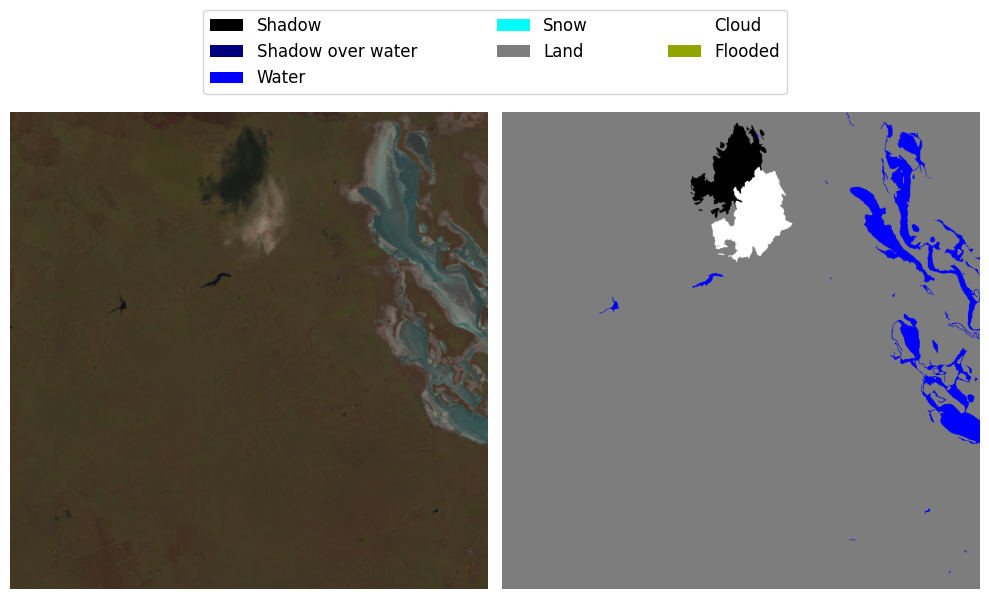

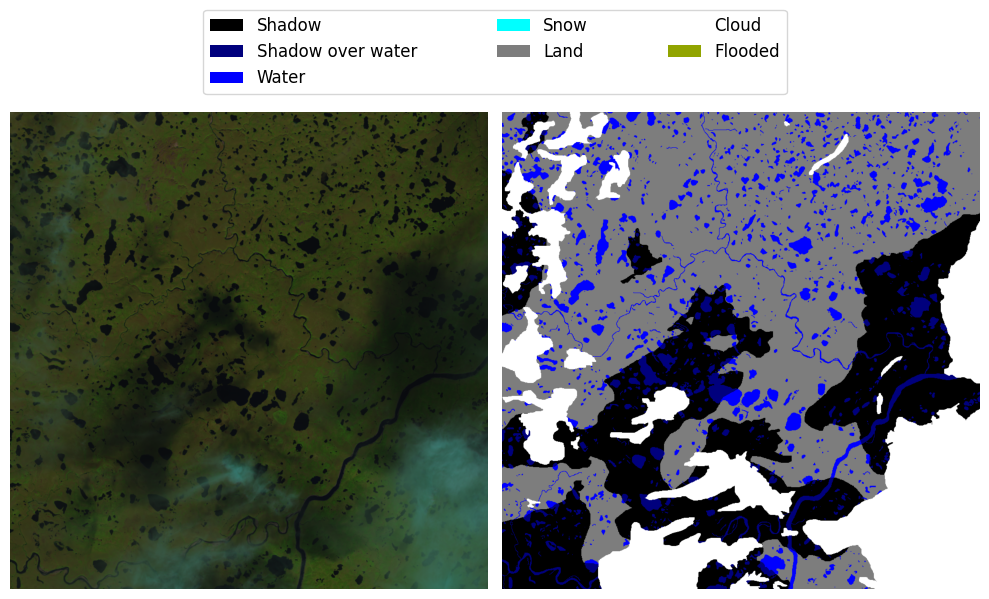

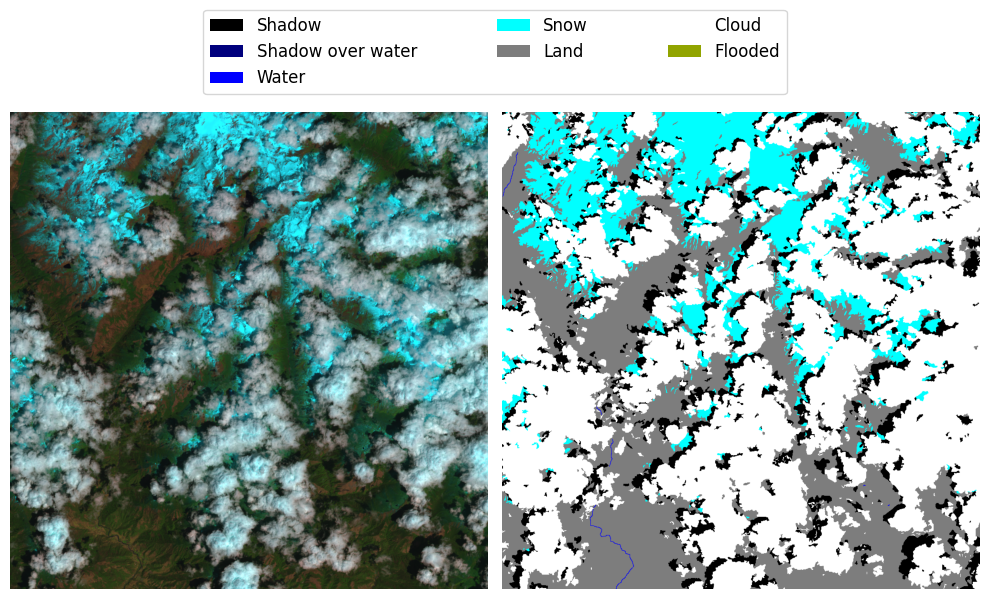

In [ ]:
dataset_config = {
    "data_dir": "./data/SPARCS"
}
dataset = SPARCSDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(15);
dataset.show_image(30);

In [22]:
dataset.data_distribution_table()

,Number of pixels
Shadow,5691893.0
Shadow over water,207571.0
Water,4521053.0
Snow,4241560.0
Land,48661508.0
Cloud,15497471.0
Flooded,1178945.0


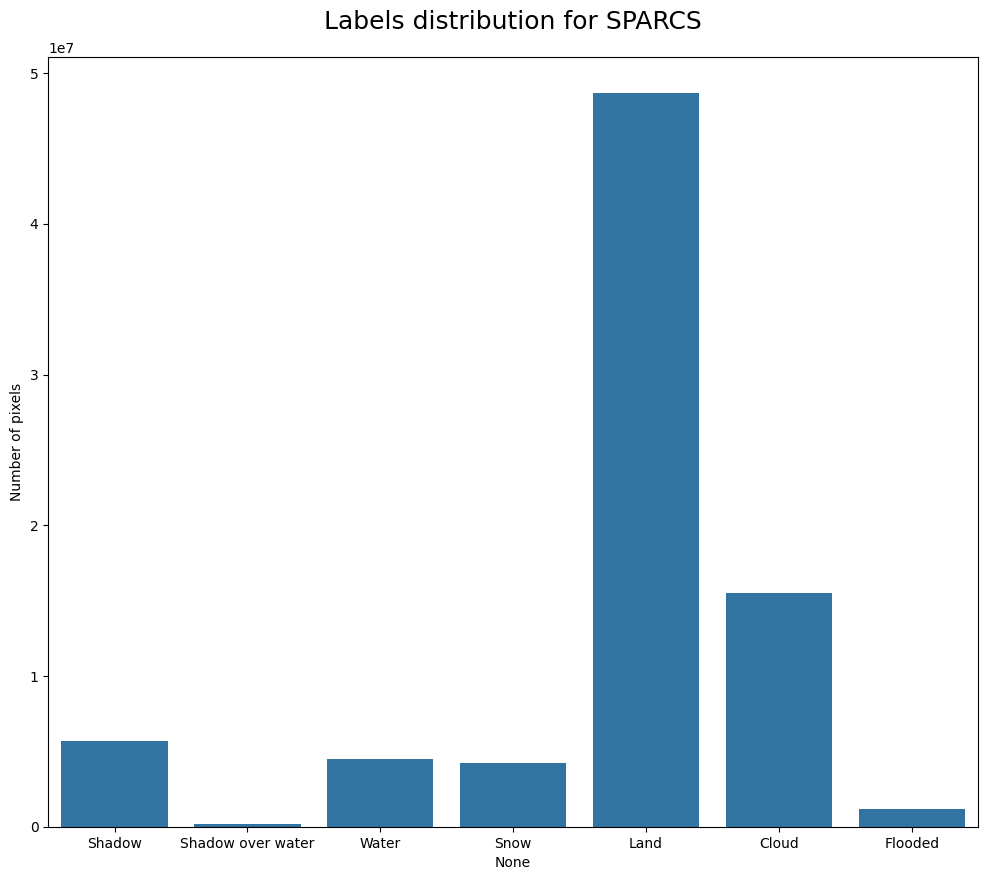

In [23]:
dataset.data_distribution_barchart();

## Load training data

In [ ]:
train_dataset_config = {
    "batch_size": 4,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/SPARCS",
    "csv_file": "./data/SPARCS/train.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = SPARCSDataset(train_dataset_config)
len(train_dataset)

64

## Create the model

In [ ]:
epochs = 10
model_directory = "./data/SPARCS"
model_config = {
    "num_classes": 7, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [7]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-02-25 09:07:50,166 INFO Starting training.
training: 100%|██████████| 16/16 [00:01<00:00,  8.12it/s]
2025-02-25 09:07:52,186 INFO epoch: 1, time: 2, loss:  0.75035
testing on train set: 100%|██████████| 16/16 [00:01<00:00,  9.97it/s]
2025-02-25 09:07:55,133 INFO IOU:0.19998342431444208, IOU mean:0.17784558202630493, IOU per Class:[2.79494231e-02 3.35022186e-04 1.23407649e-01 2.86827899e-01
 5.54799010e-01 2.44690132e-01 6.90993860e-03]
training: 100%|██████████| 16/16 [00:01<00:00,  9.36it/s]
2025-02-25 09:07:56,849 INFO epoch: 2, time: 1, loss:  0.71164
testing on train set: 100%|██████████| 16/16 [00:01<00:00,  8.82it/s]
2025-02-25 09:07:58,678 INFO IOU:0.312890619940293, IOU mean:0.22120764910269725, IOU per Class:[0.03888053 0.         0.31300384 0.27030309 0.62619129 0.29231424
 0.00776056]
training: 100%|██████████| 16/16 [00:01<00:00,  8.38it/s]
2025-02-25 09:08:00,594 INFO epoch: 3, time: 2, loss:  0.67782
testing on train set: 100%|██████████| 16/16 [00:01<00:00,  9.25it/

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/SPARCS",
    "csv_file": "./data/SPARCS/val.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = SPARCSDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/SPARCS/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

8


2025-02-25 09:09:05,440 INFO Loading checkpoint /home/dragik/data/FAIR_EO/SPARCS/checkpoint.pth.tar
2025-02-25 09:09:05,780 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/SPARCS/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 2/2 [00:00<00:00,  2.81it/s]


[{'IOU': 0.5247332517562803,
  'IOU mean': 0.26159124007637097,
  'IOU per Class': array([0.09448457, 0.        , 0.56298856, 0.        , 0.58920671,
         0.58445884, 0.        ])}]

## Predictions

2025-03-10 09:43:54,363 INFO Loading checkpoint /home/dragik/data/FAIR_EO/SPARCS/checkpoint.pth.tar
2025-03-10 09:43:54,887 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/SPARCS/checkpoint.pth.tar at epoch 11


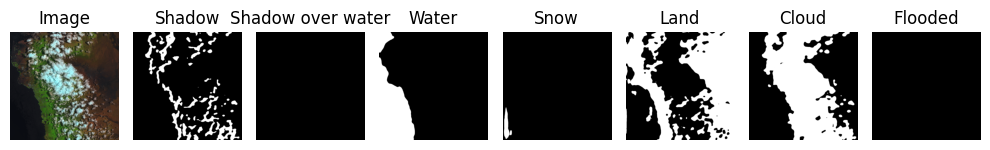

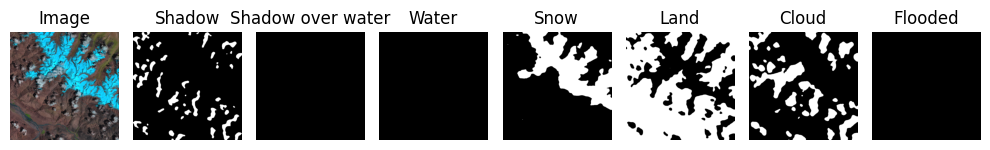

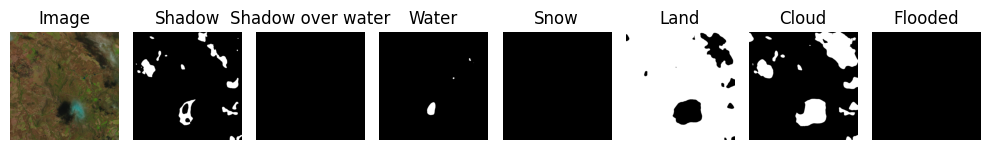

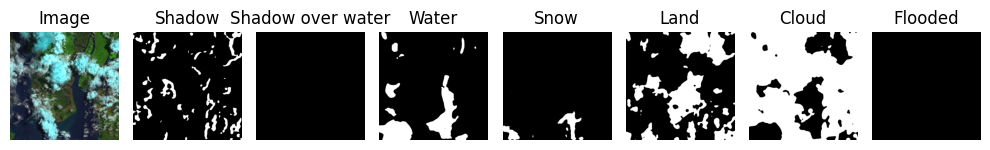

In [ ]:
model_path = "./data/SPARCS/checkpoint.pth.tar"
labels = ["Shadow","Shadow over water","Water","Snow","Land","Cloud","Flooded"]
transform = MinMaxNormTranspose()
model.load_model(model_path)
csv_file = "./data/SPARCS/test.csv"

test_list = []
with open(csv_file, mode ='r')as file:
    csvFile = csv.reader(file)
    for lines in csvFile:
        test_list.append(lines[0])

image = image_loader('./data/SPARCS/' + test_list[0])
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/SPARCS/' + test_list[2])
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/SPARCS/' + test_list[4])
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/SPARCS/' + test_list[6])
fig = model.predict_masks(image, labels, transform)